In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(context = 'notebook',
              style = 'darkgrid',
              palette = 'deep',
              font = 'sans-serif',
              font_scale = 1,
              color_codes = True,
              rc = None)

from tqdm import tqdm

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter

# Graph import

In [4]:
def parse_network_data(file_path):
    """
    Parse the mixed-format network data file into a pandas DataFrame.

    Args:
        file_path (str): Path to the input file.

    Returns:
        pd.DataFrame: A DataFrame with columns ['Source', 'Target', 'Weight', 'Timestamp'].
    """
    def parse_mixed_format(row):
        parts = row.strip().split('\t')
        if len(parts) >= 3:
            last_part = parts[-1].split()  # Split the last part to extract the timestamp
            if len(last_part) == 2:
                parts[-1], timestamp = last_part  # Adjust the last column and extract the timestamp
                return parts + [timestamp]
        return None

    # Read the raw content and parse the rows
    with open(file_path, 'r') as file:
        raw_content = file.readlines()

    parsed_data = [
        parse_mixed_format(line)
        for line in raw_content
        if not line.startswith('%') and parse_mixed_format(line) is not None
    ]

    # Create a DataFrame and convert columns to appropriate types
    columns = ['Source', 'Target', 'Weight', 'Timestamp']
    dataframe = pd.DataFrame(parsed_data, columns=columns).astype(int)

    dataframe['Datetime'] = pd.to_datetime(dataframe['Timestamp'], unit='s')

    return dataframe

def create_cumulative_graph(dataframe, timestamp_index):
    """
    Create a cumulative NetworkX graph up to a given timestamp index.

    Args:
        dataframe (pd.DataFrame): A DataFrame containing network data with 'Timestamp'.
        timestamp_index (int): Index (0-based) corresponding to the desired timestamp.

    Returns:
        networkx.Graph: A cumulative graph up to the specified timestamp.
    """
    # Ensure the DataFrame is sorted by timestamp
    dataframe = dataframe.sort_values('Timestamp')

    # Get unique timestamps and validate the index
    unique_timestamps = sorted(dataframe['Timestamp'].unique())
    if timestamp_index < 0 or timestamp_index >= len(unique_timestamps):
        raise ValueError(f"Timestamp index must be between 0 and {len(unique_timestamps) - 1}.")

    # Filter the data up to the specified timestamp
    cutoff_timestamp = unique_timestamps[timestamp_index]
    cumulative_data = dataframe[dataframe['Timestamp'] <= cutoff_timestamp]

    # Create the graph
    G = nx.Graph()
    for _, row in cumulative_data.iterrows():
        if row['Source'] != row['Target']:  # Ignore self-loops
            G.add_edge(row['Source'], row['Target'])

    return G

In [5]:
network_pandas = parse_network_data('test_networks/out.dblp-cite')

In [6]:
network_pandas

,Source,Target,Weight,Timestamp,Datetime
0,1,2,1,820454461,1996-01-01 00:01:01
1,1,3,1,820454461,1996-01-01 00:01:01
2,10001,10002,1,915148861,1999-01-01 00:01:01
3,10001,10003,1,915148861,1999-01-01 00:01:01
4,10001,10004,1,915148861,1999-01-01 00:01:01
...,...,...,...,...,...
49754,9996,8019,1,725846461,1993-01-01 00:01:01
49755,9996,880,1,725846461,1993-01-01 00:01:01
49756,9996,954,1,725846461,1993-01-01 00:01:01
49757,9996,9993,1,725846461,1993-01-01 00:01:01


## Explore the network over time

In [7]:
len(network_pandas['Timestamp'].unique())

30

In [8]:
nodes = []
edges = []
avg_degrees = []
times = sorted(network_pandas['Datetime'].unique())
for i in tqdm(range(len(network_pandas['Timestamp'].unique()))):
    g = create_cumulative_graph(network_pandas, i)
    node = g.number_of_nodes()
    edge = g.number_of_edges()
    avg_degree = 2 * edge / node
    nodes.append(node)
    edges.append(edge)
    avg_degrees.append(avg_degree)

100%|██████████| 30/30 [00:25<00:00,  1.20it/s]


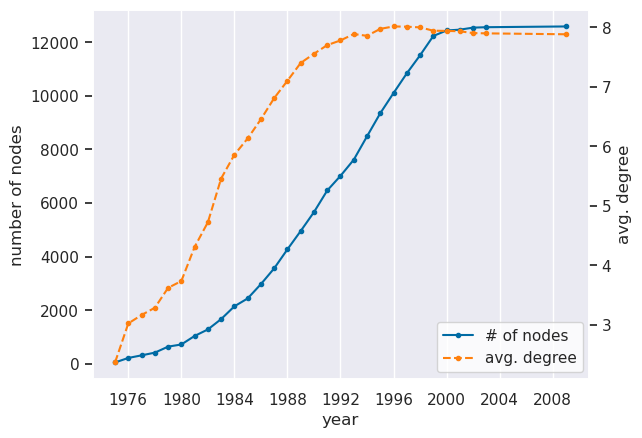

In [9]:
fig, ax = plt.subplots()
ax.plot(times,nodes,color='#006BA4',label='# of nodes',marker='.')
ax.set_xlabel('year')
ax.set_ylabel('number of nodes')
ax2 = ax.twinx()
ax2.plot(times,avg_degrees,color='#FF800E',label='avg. degree',marker='.',linestyle='--')
ax2.set_ylabel('avg. degree')
ax.grid(False)
ax2.grid(False)
fig.legend(loc=(0.68,0.15),facecolor='white')
ax.xaxis.grid(True)
plt.savefig('./figures/dblp_cite_growth_over_time.pdf', dpi = 1000, bbox_inches='tight')
plt.show()

In [10]:
G_start = create_cumulative_graph(network_pandas, 2)

In [11]:
G = G_start

In [12]:
len(G)

314

In [13]:
2 * G.number_of_edges() / G.number_of_nodes()

3.1656050955414012

In [51]:
for m_size in [2,3,5,6,7]:
    print(m_size,' k_max: ',int(np.log(len(G))/(np.log(m_size)))+1)

2  k_max:  9
3  k_max:  6
5  k_max:  4
6  k_max:  4
7  k_max:  3


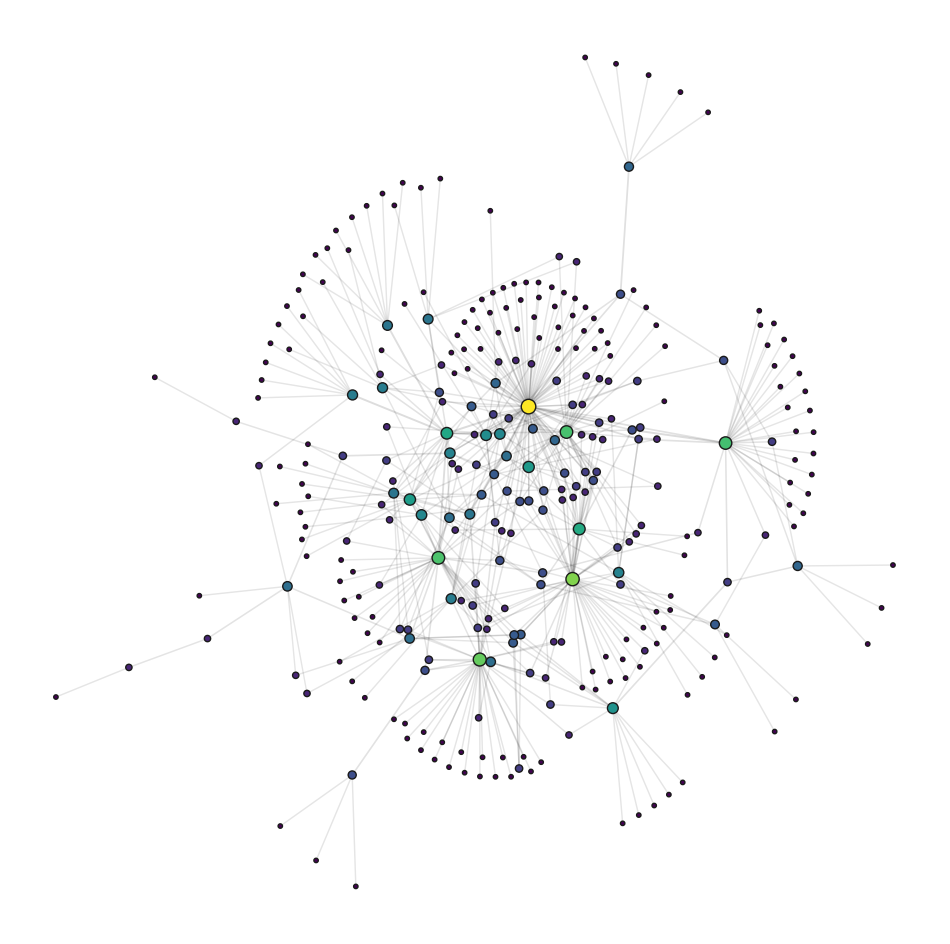

In [16]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm

# Keep only the largest connected component
largest_cc = max(nx.connected_components(G), key=len)
G_largest = G.subgraph(largest_cc).copy()

# Sort nodes by degree (ascending), so high-degree nodes are processed last
sorted_nodes = sorted(G_largest.nodes(), key=lambda x: G_largest.degree[x], reverse=True)

# Relabel the graph nodes to ensure sorted order is reflected
mapping = {node: i for i, node in enumerate(sorted_nodes)}
G_largest = nx.relabel_nodes(G_largest, mapping)

# Recalculate node degrees (now sorted)
degree = dict(G_largest.degree())
nx.set_node_attributes(G_largest, degree, 'degree')

# Node size based on degree (logarithmic scaling)
degrees = np.array(list(degree.values()))
degrees += 1  # Avoid log(0) by shifting values
node_sizes = 10 + 100 * (np.log(degrees) - np.log(degrees.min())) / (
    np.log(degrees.max()) - np.log(degrees.min())
)

# Node color based on degree (logarithmic scaling)
cmap = plt.cm.viridis
node_colors = cmap((np.log(degrees) - np.log(degrees.min())) / (np.log(degrees.max()) - np.log(degrees.min())))

# Calculate edge betweenness centrality (for edge width and alpha)
edge_betweenness = nx.edge_betweenness_centrality(G_largest)
edge_widths = [1 + 7 * edge_betweenness[edge] for edge in G_largest.edges()]  # Scale edge widths for visibility
edge_alphas = [0.1 + 0.6 * edge_betweenness[edge] for edge in G_largest.edges()]  # Scale alpha from 0.1 to 1.0

# Positioning nodes using a force-directed layout
pos = nx.kamada_kawai_layout(G_largest)

# Plot the network
plt.figure(figsize=(12, 12))
# Draw edges with scaled widths and alphas
for edge, width, alpha in zip(G_largest.edges(), edge_widths, edge_alphas):
    nx.draw_networkx_edges(
        G_largest,
        pos,
        edgelist=[edge],
        width=width,
        alpha=alpha,
        edge_color="black",
    )

# Draw nodes with size and color mapped to attributes
nx.draw_networkx_nodes(
    G_largest,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=cmap,
    edgecolors='k',  # Add a border to nodes for clarity
)

# Remove labels and title for a cleaner plot
plt.gca().set_facecolor("black")

# Hide axes for cleaner visualization
plt.axis('off')
plt.savefig('./figures/dblp_cite_314_nodes_layout.pdf', dpi = 1000, bbox_inches='tight')
plt.show()

# Init Fitter

In [14]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.019879
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.426570


In [15]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 497},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 8774},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 63},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 168969},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 0},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 21757},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 4015},
 {'name': 'four_loop

# Grid Search

In [32]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,9]},
                {'m': 3,  'k': [1,6]},
                {'m': 5,  'k': [1,4]},
                {'m': 6,  'k': [1,4]},
                {'m': 7,  'k': [1,3]},],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'energy'
)

[I 2025-02-20 08:30:19,305] A new study created in memory with name: no-name-4dee8fc4-fbb9-4eef-afa8-72ce8ea705ca


Grid Search requires 8 trials...


[I 2025-02-20 08:30:27,020] Trial 0 finished with value: 13.31110658136801 and parameters: {'m': 2, 'k': 7}. Best is trial 0 with value: 13.31110658136801.
[I 2025-02-20 08:30:35,455] Trial 1 finished with value: 13.058146344729256 and parameters: {'m': 2, 'k': 3}. Best is trial 1 with value: 13.058146344729256.
[I 2025-02-20 08:30:41,995] Trial 2 finished with value: 13.075387391634177 and parameters: {'m': 2, 'k': 2}. Best is trial 1 with value: 13.058146344729256.
[I 2025-02-20 08:30:50,971] Trial 3 finished with value: 14.024507016098559 and parameters: {'m': 2, 'k': 8}. Best is trial 1 with value: 13.058146344729256.
[I 2025-02-20 08:30:57,998] Trial 4 finished with value: 13.14036703606088 and parameters: {'m': 2, 'k': 4}. Best is trial 1 with value: 13.058146344729256.
[I 2025-02-20 08:31:05,339] Trial 5 finished with value: 13.22497907035558 and parameters: {'m': 2, 'k': 1}. Best is trial 1 with value: 13.058146344729256.
[I 2025-02-20 08:31:11,592] Trial 6 finished with value:

Grid Search requires 5 trials...


[I 2025-02-20 08:31:36,655] Trial 0 finished with value: 12.48983444990796 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 12.48983444990796.
[I 2025-02-20 08:31:52,685] Trial 1 finished with value: 11.794394789017925 and parameters: {'m': 3, 'k': 1}. Best is trial 1 with value: 11.794394789017925.
[I 2025-02-20 08:32:07,451] Trial 2 finished with value: 11.270924328832313 and parameters: {'m': 3, 'k': 2}. Best is trial 2 with value: 11.270924328832313.
[I 2025-02-20 08:32:25,237] Trial 3 finished with value: 12.576406377924764 and parameters: {'m': 3, 'k': 4}. Best is trial 2 with value: 11.270924328832313.
[I 2025-02-20 08:32:50,331] Trial 4 finished with value: 12.42866342131719 and parameters: {'m': 3, 'k': 5}. Best is trial 2 with value: 11.270924328832313.
[I 2025-02-20 08:32:50,332] A new study created in memory with name: no-name-fa67979b-c12e-4e3f-b72c-bb057d8385ce


Grid Search requires 3 trials...


... (2 outputs left out)

[I 2025-02-20 08:36:17,658] Trial 0 finished with value: 11.83875766146727 and parameters: {'m': 6, 'k': 3}. Best is trial 0 with value: 11.83875766146727.
[I 2025-02-20 08:37:17,584] Trial 1 finished with value: 11.15688609994119 and parameters: {'m': 6, 'k': 2}. Best is trial 1 with value: 11.15688609994119.
[I 2025-02-20 08:37:59,925] Trial 2 finished with value: 11.985865241632288 and parameters: {'m': 6, 'k': 1}. Best is trial 1 with value: 11.15688609994119.
[I 2025-02-20 08:37:59,926] A new study created in memory with name: no-name-7644e901-afcc-4800-93f6-2447a653dde1


Grid Search requires 2 trials...


[I 2025-02-20 08:39:27,078] Trial 0 finished with value: 11.164790611462033 and parameters: {'m': 7, 'k': 2}. Best is trial 0 with value: 11.164790611462033.
[I 2025-02-20 08:40:08,370] Trial 1 finished with value: 11.224578249145218 and parameters: {'m': 7, 'k': 1}. Best is trial 0 with value: 11.164790611462033.


Best parameters:  {'m': 5, 'k': 1}
Best energy:  11.08423232349914
Best KL-divergence:  0.09143908117202902
Best KLD augumented energy: 5.289236243580942
Best P matrix:
 [[1.45437535e-06 1.01942276e-02 8.86047729e-02 1.44301792e-01
  3.18238289e-01]
 [1.01942276e-02 9.92276823e-02 7.46967104e-02 1.72391217e-01
  3.55732320e-01]
 [8.86047729e-02 7.46967104e-02 1.44306436e-01 1.66100763e-01
  2.09350946e-01]
 [1.44301792e-01 1.72391217e-01 1.66100763e-01 3.58314573e-01
  2.79069194e-01]
 [3.18238289e-01 3.55732320e-01 2.09350946e-01 2.79069194e-01
  2.50826146e-01]]
Best l vector:
 [0.84910202 0.11933044 0.02913221 0.00209109 0.00170323]


Energy: 11.14243606652993
KL-divergence: 0.12826468352322085
KLD augumented energy: 5.894185390446013


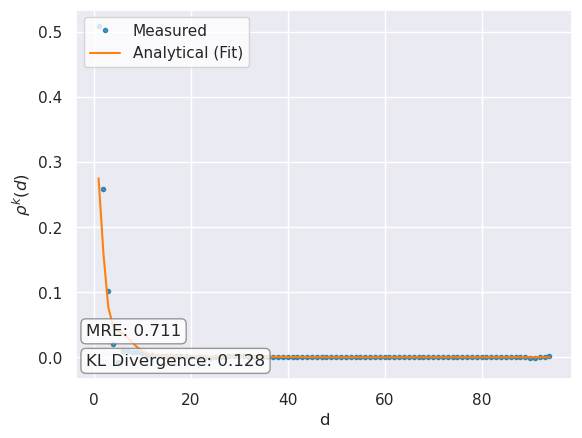

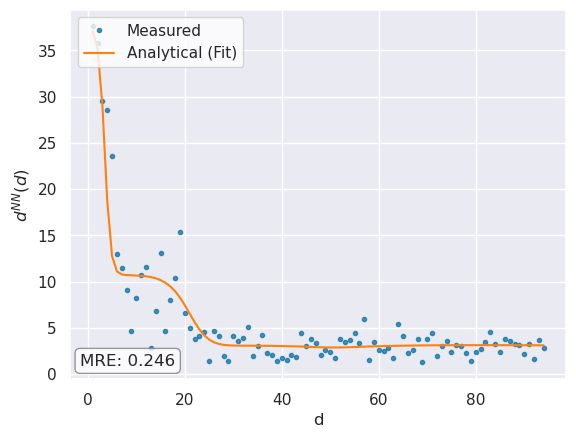

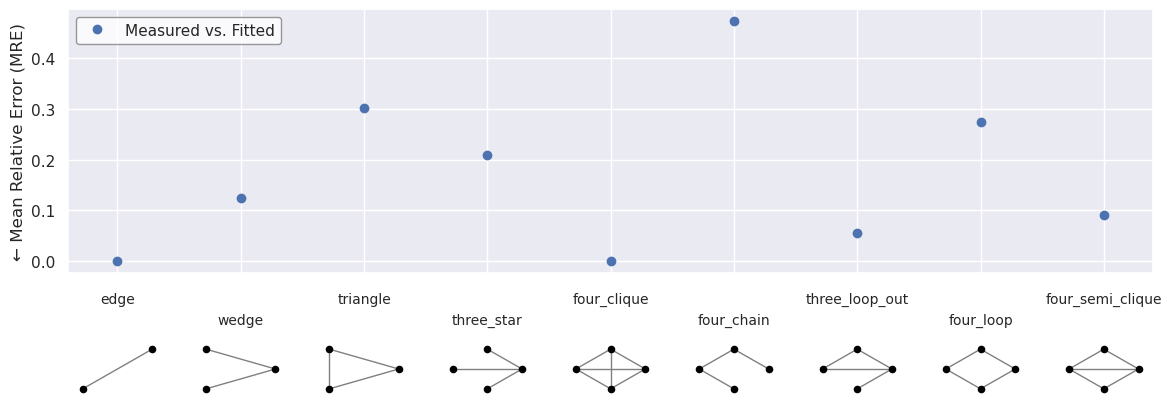

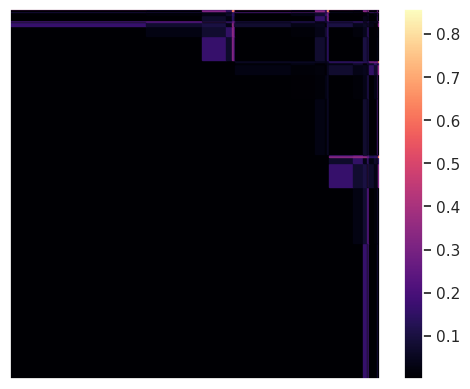

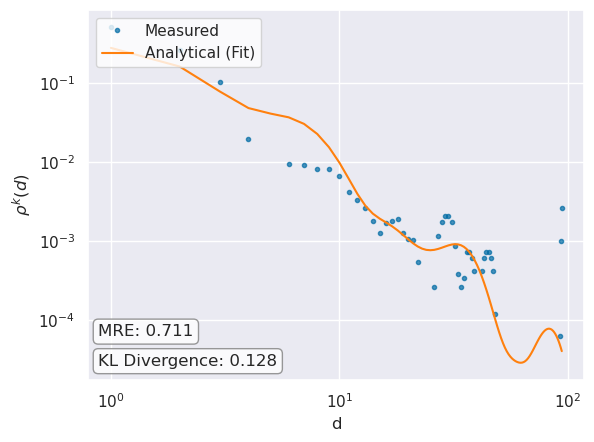

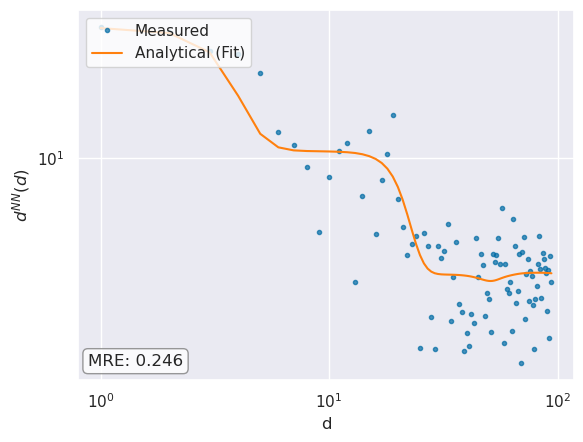

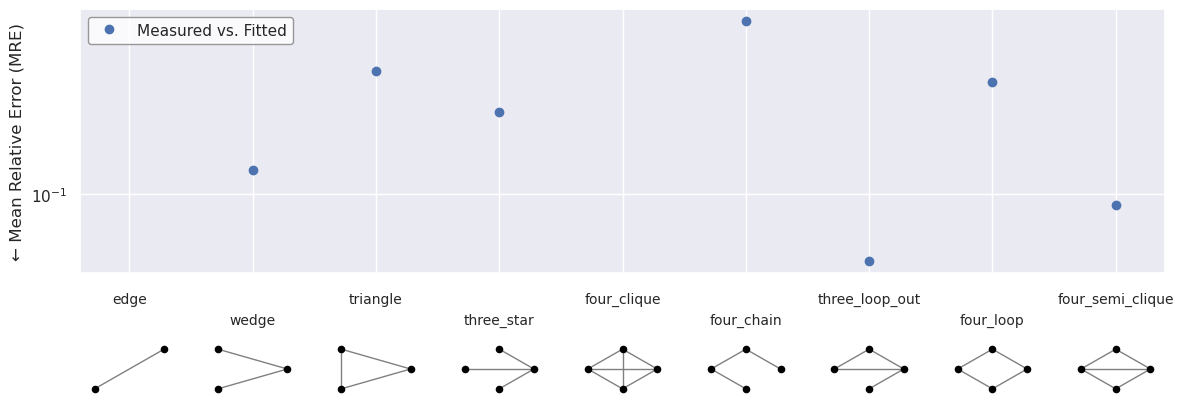

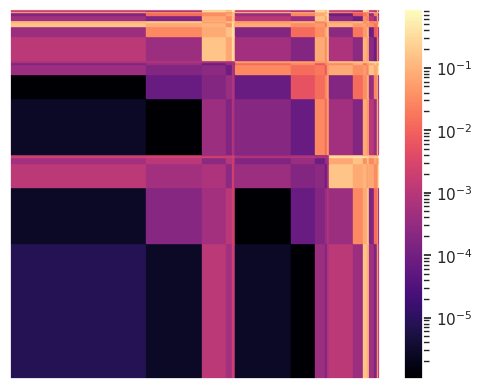

In [36]:
mfnf.find_P_l(7,2, one_shot=True)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
)

In [ ]:
# We choose 7-2, as the 'best' measures result in k+1-s, that corresponds to networks with 100k nodes, 
# which is too large for this dataset.

# Bootstrap Stability

In [39]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'lowest'
)

Gathering statistics (30 runs)...


100%|██████████| 30/30 [44:11<00:00, 88.37s/it]

Bootstrapping: Resampling 100 times...


Bootstrapping finished in 0:00:00.265025
Energy = 10.86 (10.86, 11.56)
l = [0.73 (0.47, 0.86), 0.09 (0.05, 0.38), 0.09 (0.02, 0.11), 0.05 (0.01, 0.10), 0.03 (0.00, 0.05), 0.00 (0.00, 0.03), 0.00 (0.00, 0.03)]
P = [
[0.00 (0.00, 0.05), 0.00 (0.00, 0.38), 0.31 (0.00, 0.64), 0.33 (0.00, 0.89), 0.12 (0.00, 0.99), 0.95 (0.05, 0.98), 0.43 (0.01, 0.97)],

[0.00 (0.00, 0.38), 0.25 (0.00, 0.81), 0.00 (0.01, 0.55), 0.63 (0.02, 0.73), 0.40 (0.05, 0.95), 0.89 (0.00, 0.98), 0.65 (0.00, 0.99)],

[0.31 (0.00, 0.64), 0.00 (0.01, 0.55), 0.75 (0.06, 0.90), 0.01 (0.01, 0.99), 0.27 (0.00, 0.85), 0.34 (0.01, 0.99), 0.13 (0.02, 0.88)],

[0.33 (0.00, 0.89), 0.63 (0.02, 0.73), 0.01 (0.01, 0.99), 0.68 (0.02, 0.98), 0.42 (0.04, 0.92), 0.75 (0.04, 0.91), 0.36 (0.01, 0.90)],

[0.12 (0.00, 0.99), 0.40 (0.05, 0.95), 0.27 (0.00, 0.85), 0.42 (0.04, 0.92), 0.35 (0.01, 0.99), 0.90 (0.00, 0.94), 0.47 (0.04, 0.90)],

[0.95 (0.05, 0.98), 0.89 (0.00, 0.98), 0.34 (0.01, 0.99), 0.75 (0.04, 0.91), 0.90 (0.00, 0.94), 0.88 (0.0

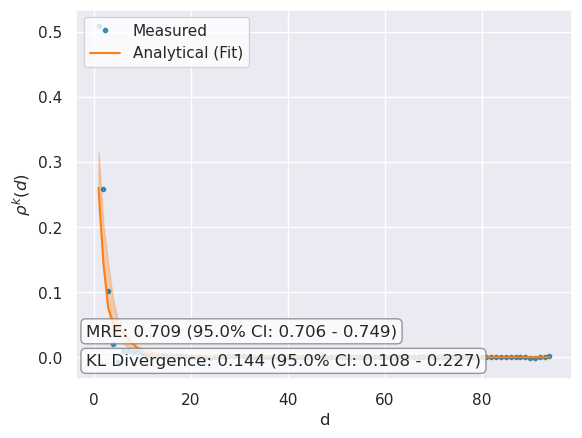

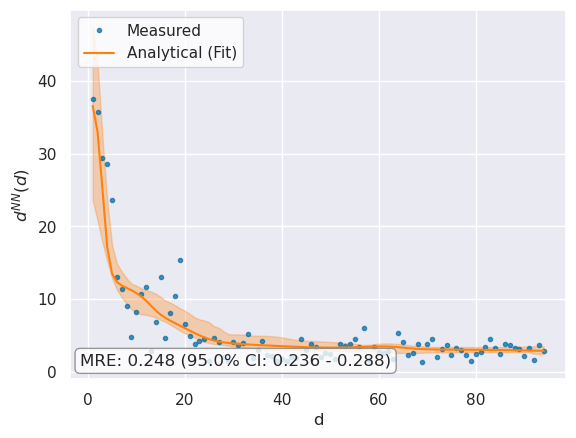

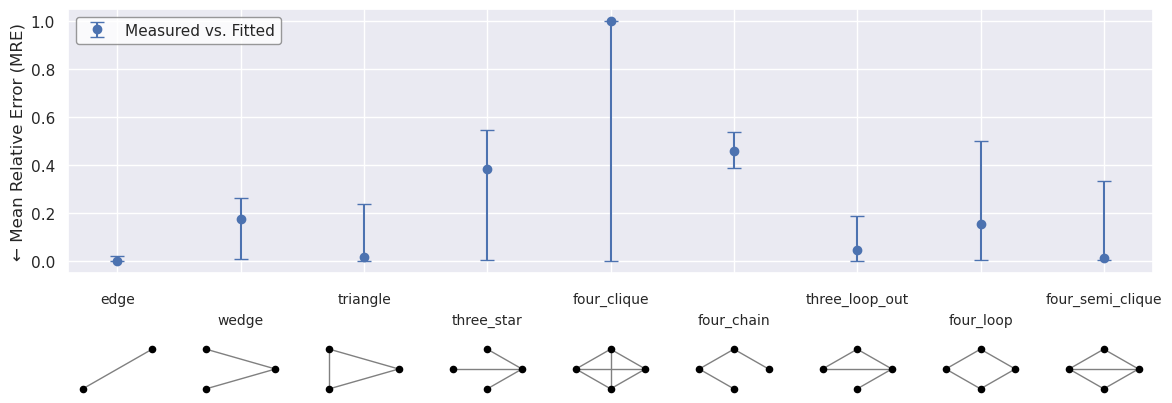

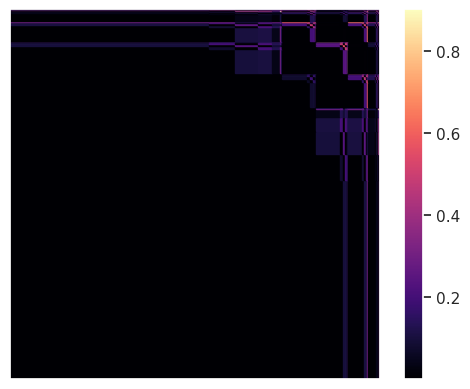

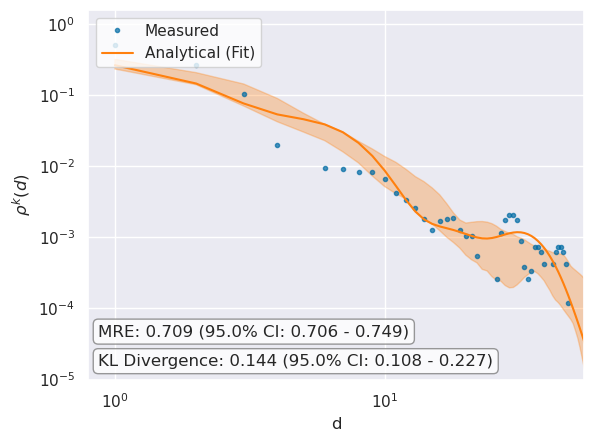

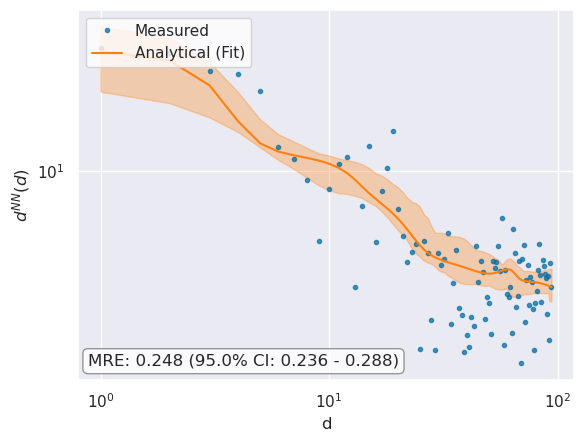

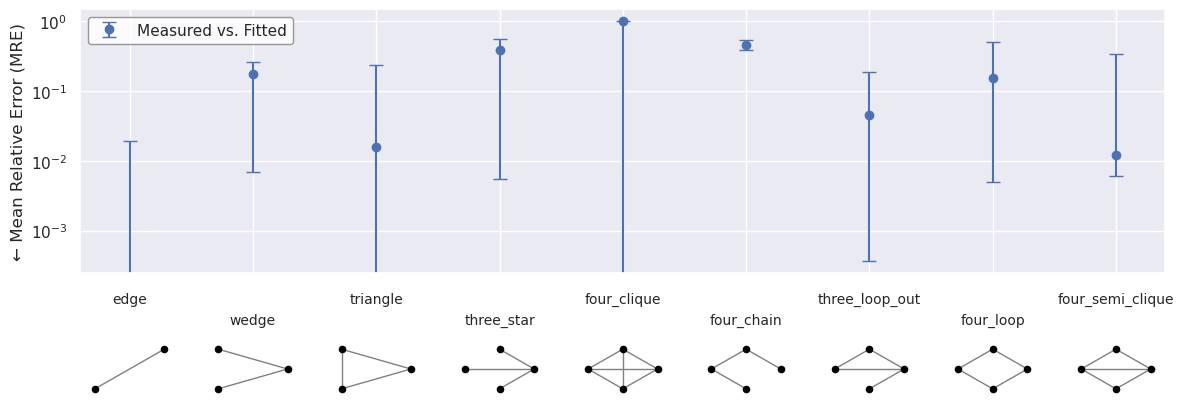

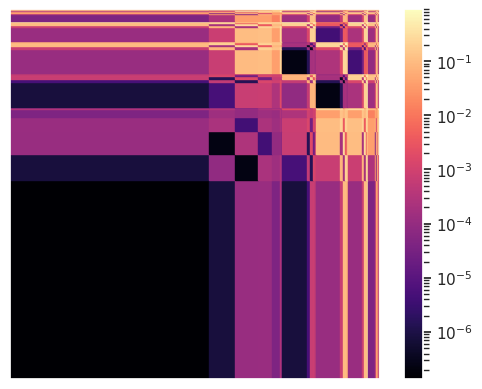

In [64]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/dblp_cite_300_nodes_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    xlim = (0,55),
    ylim = (1e-5,0),
    filename = "figures/dblp_cite_300_nodes_log_plot.pdf"
)

In [63]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 497,
  'expected_count': 497,
  'MRE': 0.0,
  'expected_count_ci_low': 489.0,
  'expected_count_ci_high': 503.525,
  'MRE_ci_low': 0.0,
  'MRE_ci_high': 0.01901398548772948},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 8774,
  'expected_count': 7255,
  'MRE': 0.17312514246637795,
  'expected_count_ci_low': 6465.275,
  'expected_count_ci_high': 8865.0,
  'MRE_ci_low': 0.006850500523839164,
  'MRE_ci_high': 0.26313255071803054},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 63,
  'expected_count': 62,
  'MRE': 0.015873015873015872,
  'expected_count_ci_low': 48.0,
  'expected_count_ci_high': 69.57499999999997,
  'MRE_ci_low': 0.0,
  'MRE_ci_high': 0.23809523809523808},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 

In [62]:
import pickle
with open('./test_networks/dblp_cite_300_nodes_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf, f)

# Scaling the network

## k = 2 -> 3

In [13]:
import pickle
with open('./test_networks/dblp_cite_300_nodes_mfnf.pkl', 'rb') as f:
    mfnf = pickle.load(f)

In [17]:
mfnf.motifs[0]

{'name': 'edge',
 'matrix': array([[0, 1],
        [1, 0]]),
 'size': 2,
 'count': 497,
 'expected_count': 497,
 'MRE': 0.0,
 'expected_count_ci_low': 489.0,
 'expected_count_ci_high': 503.525,
 'MRE_ci_low': 0.0,
 'MRE_ci_high': 0.01901398548772948}

In [29]:
def calculate_k_new(N_new, edge_density, P, l):
    sum_term = np.sum(np.outer(l, l) * P)
    # Calculate the numerator of the logarithm
    numerator_1 = 2  / (N_new - 1)
    # Calculate k_new using the formula
    k_new = np.log(numerator_1 * edge_density) / np.log(sum_term)
    return k_new

In [43]:
print('k_new','\t\t\t','time','\t\t\t','num_of_nodes','\t','i')
for i in range(0,30):
    print(calculate_k_new(nodes[i],edges[i]/nodes[i],mfnf.P,mfnf.l),'\t', times[i],'\t', nodes[i],'\t\t', i)

k_new 			 time 			 num_of_nodes 	 i
1.310272744907734 	 1975-01-01 00:01:01 	 49 		 0
1.8586815071091822 	 1976-01-01 00:01:01 	 217 		 1
2.0001149606787125 	 1977-01-01 00:01:01 	 314 		 2
2.105526382292802 	 1978-01-01 00:01:01 	 415 		 3
2.2516177027276356 	 1979-01-01 00:01:01 	 639 		 4
2.2900652665825465 	 1980-01-01 00:01:01 	 720 		 5
2.3872806441900654 	 1981-01-01 00:01:01 	 1038 		 6
2.438990669060858 	 1982-01-01 00:01:01 	 1281 		 7
2.490734314223898 	 1983-01-01 00:01:01 	 1667 		 8
2.569577748583031 	 1984-01-01 00:01:01 	 2144 		 9
2.605681326017873 	 1985-01-01 00:01:01 	 2438 		 10
2.6697434673449103 	 1986-01-01 00:01:01 	 2973 		 11
2.7250164047180507 	 1987-01-01 00:01:01 	 3561 		 12
2.7859444395526047 	 1988-01-01 00:01:01 	 4271 		 13
2.832747455350824 	 1989-01-01 00:01:01 	 4956 		 14
2.881671383089333 	 1990-01-01 00:01:01 	 5661 		 15
2.931355209450112 	 1991-01-01 00:01:01 	 6467 		 16
2.962205567877921 	 1992-01-01 00:01:01 	 7013 		 17
2.992173395387931 	

In [46]:
k_for_i = []
for i in range(0,30):
    k_for_i.append(round(calculate_k_new(nodes[i],edges[i]/nodes[i],mfnf.P,mfnf.l)))

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from copy import deepcopy

results = {
    'rho_mre': [],
    'rho_kld': [],
    'deg_nn_mre': [],
    'motifs': []
}

In [61]:
for i in range(3,30):
    print(i)
    G_i = create_cumulative_graph(network_pandas, i)
    mfnf_i = MultifractalNetworkFitter(
        G_i,                                   
        motifs = [
            {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
            {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
            {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
            {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
        ],
        sampling_ratios = {
            3: 0.01,
            4: 0.0001
        },
        motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
        population_size = 100,
        weights = {
            'rho':9,
            'deg_nn':9,
            'motifs':1,
            'edge':9
        }
    )
    mfnf_i.save_motifs(f'./test_networks/dblp_cite_{i}_motifs.pkl')
    mfnf_i.P = deepcopy(mfnf.P)
    mfnf_i.l = deepcopy(mfnf.l)
    mfnf_i.k = k_for_i[i]
    mfnf_i.resampled_best_candidates = deepcopy(mfnf.resampled_best_candidates)
    mfnf_i.resampled_best_energies = deepcopy(mfnf.resampled_best_energies)
    mfnf_i.bootstrap = True
    mfnf_i._calculate_bootstrap_metrics(ci = 0.95, medoid = 'lowest')

    # Store metrics in DataFrames
    timestamp = times[i]
    
   # Store rho MRE
    results['rho_mre'].append({
        'timestamp': timestamp,
        'value': mfnf_i.rho_analytical['mre'],
        'ci_low': mfnf_i.rho_analytical['mre_ci_low'],
        'ci_high': mfnf_i.rho_analytical['mre_ci_high']
    })
    
    # Store rho KLD
    results['rho_kld'].append({
        'timestamp': timestamp,
        'value': mfnf_i.rho_analytical['kld'],
        'ci_low': mfnf_i.rho_analytical['kld_ci_low'],
        'ci_high': mfnf_i.rho_analytical['kld_ci_high']
    })
    
    # Store deg_nn MRE
    results['deg_nn_mre'].append({
        'timestamp': timestamp,
        'value': mfnf_i.deg_nn_analytical['mre'],
        'ci_low': mfnf_i.deg_nn_analytical['mre_ci_low'],
        'ci_high': mfnf_i.deg_nn_analytical['mre_ci_high']
    })
    
    # Store motif metrics
    for j, motif in enumerate(mfnf_i.motifs):
        results['motifs'].append({
            'timestamp': timestamp,
            'motif_name': motif['name'],
            'value': motif['MRE'],
            'ci_low': motif['MRE_ci_low'],
            'ci_high': motif['MRE_ci_high']
        })

# Convert results to DataFrames
rho_mre_df = pd.DataFrame(results['rho_mre'])
rho_kld_df = pd.DataFrame(results['rho_kld'])
deg_nn_mre_df = pd.DataFrame(results['deg_nn_mre'])
motifs_df = pd.DataFrame(results['motifs'])

# Save DataFrames to CSV
rho_mre_df.to_csv('./test_networks/dblp_cite_over_time_rho_mre.csv', index=False)
rho_kld_df.to_csv('./test_networks/dblp_cite_over_time_rho_kld.csv', index=False)
deg_nn_df.to_csv('./test_networks/dblp_cite_over_time_deg_nn_mre.csv', index=False)
motifs_df.to_csv('./test_networks/dblp_cite_over_time_motifs_mre.csv', index=False)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.031200
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.529098
Energy = 10.86 (10.86, 11.56)
l = [0.73 (0.47, 0.86), 0.09 (0.05, 0.38), 0.09 (0.02, 0.11), 0.05 (0.01, 0.10), 0.03 (0.00, 0.05), 0.00 (0.00, 0.03), 0.00 (0.00, 0.03)]
P = [
[0.00 (0.00, 0.05), 0.00 (0.00, 0.38), 0.31 (0.00, 0.64), 0.33 (0.00, 0.89), 0.12 (0.00, 0.99), 0.95 (0.05, 0.98), 0.43 (0.01, 0.97)],

[0.00 (0.00, 0.38), 0.25 (0.00, 0.81), 0.00 (0.01, 0.55), 0.63 (0.02, 0.73), 0.40 (0.05, 0.95), 0.89 (0.00, 0.98), 0.65 (0.00, 0.99)],

[0.31 (0.00, 0.64), 0

In [106]:
def create_plot(data, x_col, y_col, low_col, high_col, name, metric_type, color='#006BA4', 
                plot_style='fill', highlight_indices=[3, 18]):
    """
    Create a plot with confidence intervals and highlighted points
    
    Parameters:
    -----------
    data : pandas.DataFrame
        DataFrame with the data
    x_col : str
        Column name for x-axis
    y_col : str
        Column name for y-axis
    low_col : str
        Column name for lower CI
    high_col : str
        Column name for upper CI
    name : str
        Name of the metric (e.g., 'rho', 'deg_nn', 'four_chain')
    metric_type : str
        Type of metric ('mre' or 'kld')
    color : str
        Color for the plot
    plot_style : str
        Style for confidence intervals: 'fill' or 'errorbar'
    highlight_indices : list
        List of indices from the original loop (i values) to select timestamps to highlight
    """
    # Set seaborn style
    sns.set_theme(
        context='paper',
        style='darkgrid',
        palette='deep',
        font='sans-serif',
        font_scale=1,
        color_codes=True
    )
    
    # Create figure
    fig, ax = plt.subplots()
    
    # Plot based on selected style
    if plot_style.lower() == 'fill':
        # Plot line
        ax.plot(data[x_col], data[y_col], color=color, linewidth=2, marker = 'o')
        
        # Add confidence intervals as shaded area
        ax.fill_between(data[x_col], data[low_col], data[high_col], color=color, alpha=0.2)
    
    elif plot_style.lower() == 'errorbar':
        # Calculate error bars
        yerr_low = data[y_col] - data[low_col]
        yerr_high = data[high_col] - data[y_col]
        yerr = np.array([yerr_low, yerr_high])
        
        # Plot with error bars
        ax.errorbar(
            data[x_col], 
            data[y_col], 
            yerr=yerr, 
            color=color, 
            linewidth=0,
            fmt='o',
            capsize=5,
            capthick=1.5,
            elinewidth=1.5
        )
    
    # Find timestamps to highlight
    highlight_timestamps = []
    
    # Our data is sorted by timestamp, with the first timestamp corresponding to i=3
    # For each i in highlight_indices, find the corresponding timestamp
    for i in highlight_indices:
        # Calculate the DataFrame index from the original loop index i
        df_index = i - 3  # Mapping from i value to position in DataFrame
        
        if df_index >= 0 and df_index < len(data):
            # For regular DataFrames
            if 'motif_name' not in data.columns:
                highlight_timestamps.append(data.iloc[df_index][x_col])
            # For motifs DataFrame, we need to filter by motif_name first
            elif 'motif_name' in data.columns and name in data['motif_name'].values:
                filtered_data = data[data['motif_name'] == name]
                if df_index < len(filtered_data):
                    highlight_timestamps.append(filtered_data.iloc[df_index][x_col])
    
    # Mark the highlighted points
    for timestamp in highlight_timestamps:
        # Find the row with this timestamp
        if 'motif_name' in data.columns:
            row = data[(data[x_col] == timestamp) & (data['motif_name'] == name)]
        else:
            row = data[data[x_col] == timestamp]
        
        if not row.empty:
            # Get the y-value
            y_value = row.iloc[0][y_col]
            
            # Add a star marker
            #ax.plot(timestamp, y_value, 'o', color=color, markersize=10, 
            #        markerfacecolor='none', markeredgewidth=2)
            ax.plot(timestamp, y_value, '*', color='red', markersize=15)
            
            # Add a bold text annotation with the timestamp value
            # Format the timestamp appropriately
            if isinstance(timestamp, (int, float)):
                # If timestamp is a number, format it with appropriate precision
                timestamp_str = f"{timestamp:.4f}"
            else:
                # If timestamp is a string or other type, convert to string
                timestamp_str = f"{timestamp.strftime("%Y")}"
                
            ax.annotate(timestamp_str, 
                       (timestamp, y_value),
                       textcoords="offset points", 
                       xytext=(10, 10),
                       fontweight='bold',
                       fontsize=12)
    
    # Set axis labels
    if metric_type.lower() == 'mre':
        y_label = '← Mean Relative Error (MRE)'
    elif metric_type.lower() == 'kld':
        y_label = '← KL-divergence'
    else:
        y_label = metric_type
    
    ax.set_xlabel('year')
    ax.set_ylabel(y_label)
    
    # Set grid
    ax.grid(True)
    
    # Save figure
    style_suffix = '_errorbar' if plot_style.lower() == 'errorbar' else ''
    filename = f'./figures/dblp_cite_over_time{name}_{metric_type}{style_suffix}.pdf'
    fig.savefig(filename, dpi=1000, bbox_inches='tight')
    filename = f'./figures_jpg/dblp_cite_over_time{name}_{metric_type}{style_suffix}.jpg'
    fig.savefig(filename, dpi=1000, bbox_inches='tight')

    # Show figure
    plt.show()
    
    # Close the figure to free memory
    plt.close(fig)

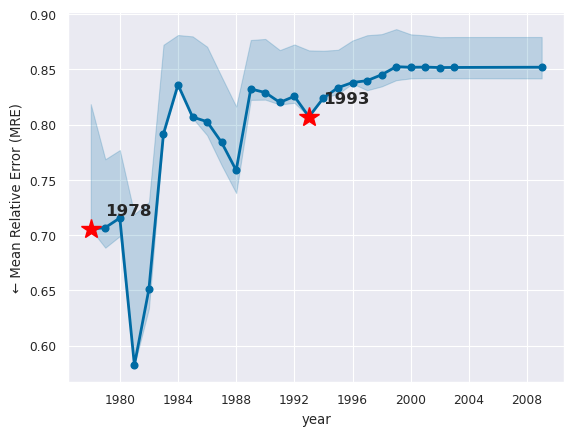

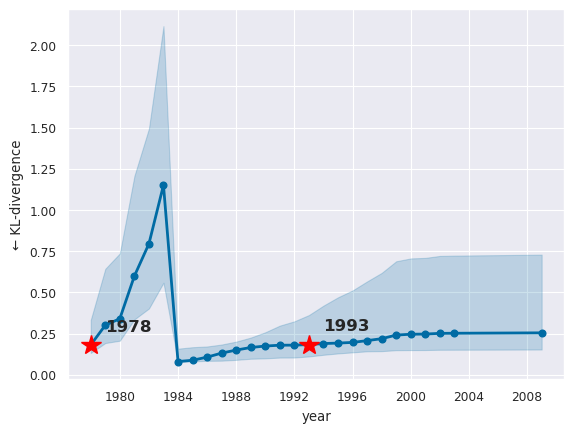

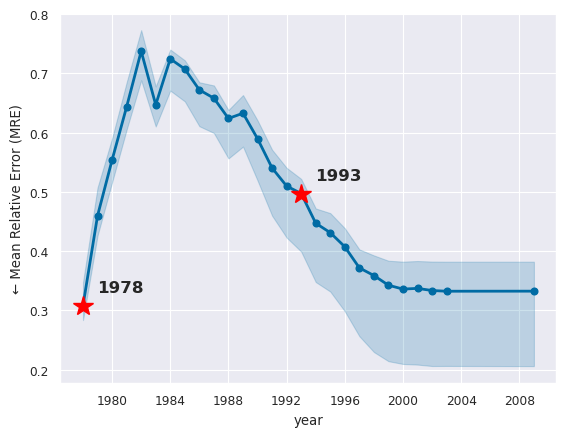

edge


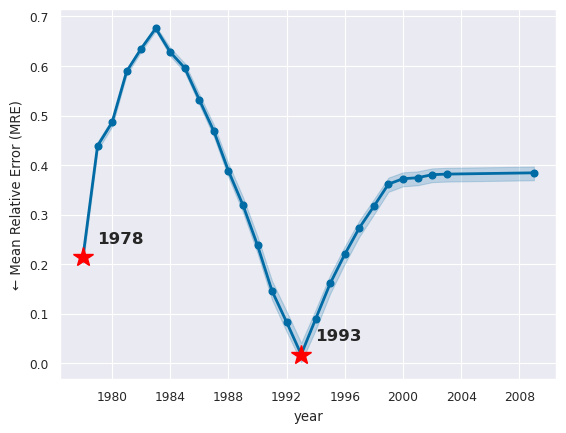

wedge


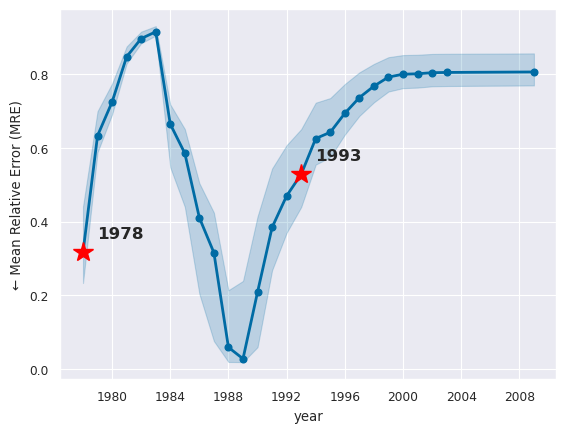

triangle


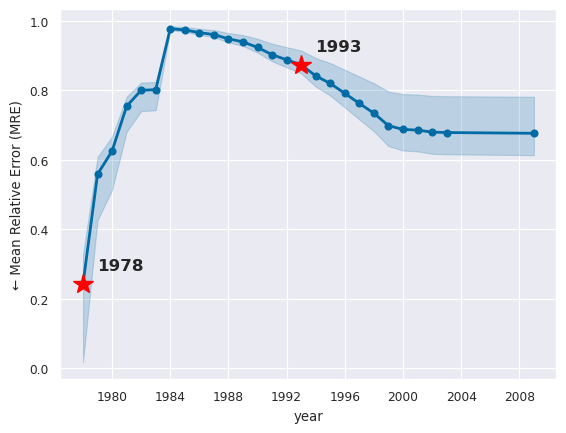

three_star


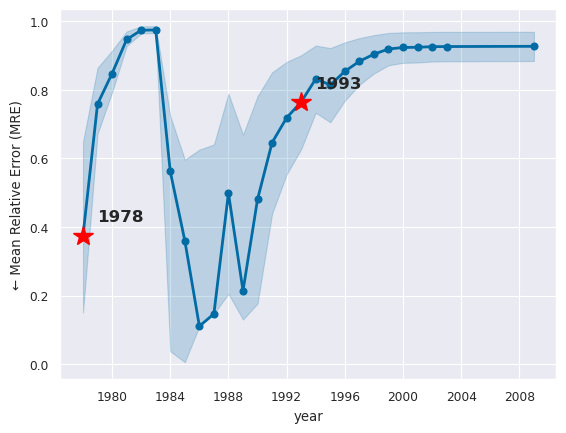

four_clique


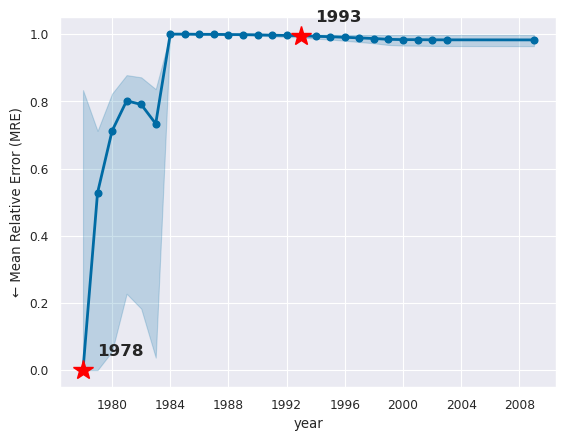

four_chain


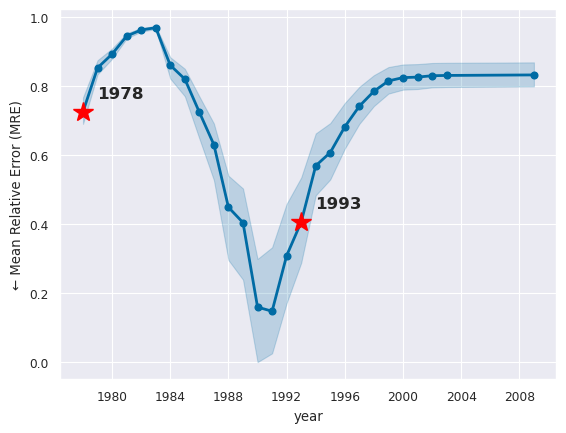

three_loop_out


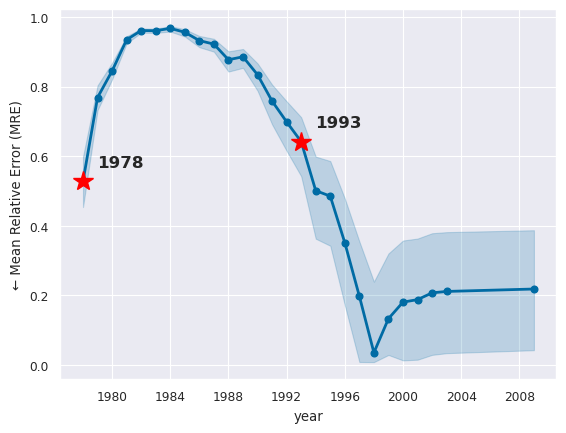

four_loop


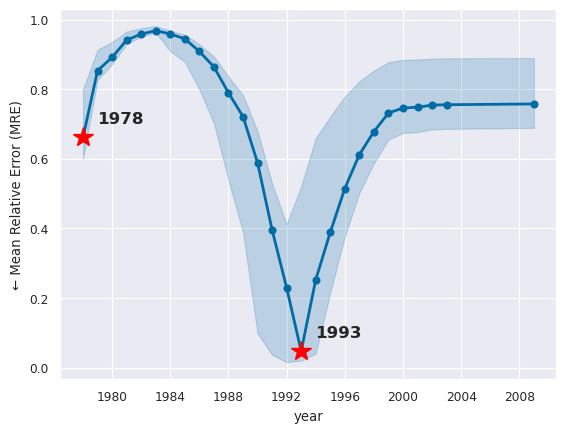

four_semi_clique


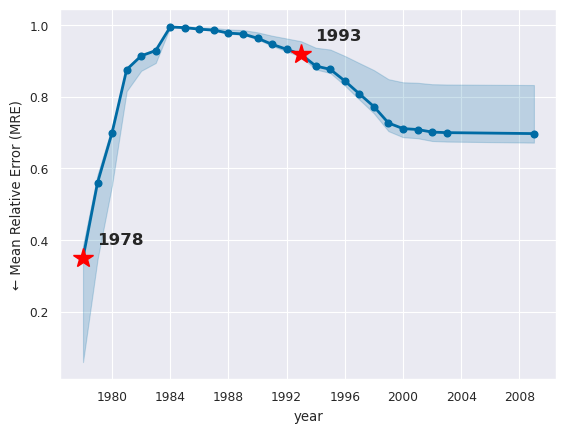

In [107]:
# Plot rho MRE
create_plot(
    rho_mre_df, 
    'timestamp', 'value', 'ci_low', 'ci_high',
    'rho', 'mre',
    #plot_style = 'errorbar'
)

# Plot rho KLD
create_plot(
    rho_kld_df, 
    'timestamp', 'value', 'ci_low', 'ci_high',
    'rho', 'kld',
    #plot_style = 'errorbar'
)

# Plot deg_nn MRE
create_plot(
    deg_nn_mre_df, 
    'timestamp', 'value', 'ci_low', 'ci_high',
    'deg_nn', 'mre',
    #plot_style = 'errorbar'
)

# Plot motif MREs
for motif_name in motifs_df['motif_name'].unique():
    print(motif_name)
    motif_data = motifs_df[motifs_df['motif_name'] == motif_name]
    create_plot(
        motif_data,
        'timestamp', 'value', 'ci_low', 'ci_high',
        motif_name, 'mre',
    #plot_style = 'errorbar'
    )

## k = 3 only

In [108]:
print(len(create_cumulative_graph(network_pandas, 18)))

7616


In [109]:
G_18 = create_cumulative_graph(network_pandas, 18)

In [110]:
mfnf_no_fit = MultifractalNetworkFitter(
    G_18,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:02.306686
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:04:02.632005


In [111]:
mfnf_no_fit.save_motifs('./test_networks/dblp_cite_7616_nodes_motifs.pkl')

In [112]:
mfnf_no_fit.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 30041},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 1072145},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 24851},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 70083755},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 11580},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 24303154},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 3886240},


In [113]:
from copy import deepcopy

In [114]:
mfnf_no_fit.P = deepcopy(mfnf.P)
mfnf_no_fit.l = deepcopy(mfnf.l)
mfnf_no_fit.k = 3
mfnf_no_fit.resampled_best_candidates = deepcopy(mfnf.resampled_best_candidates)
mfnf_no_fit.resampled_best_energies = deepcopy(mfnf.resampled_best_energies)
mfnf_no_fit.bootstrap = True
mfnf_no_fit._calculate_bootstrap_metrics(ci = 0.95, medoid = 'lowest')

Energy = 10.86 (10.86, 11.56)
l = [0.73 (0.47, 0.86), 0.09 (0.05, 0.38), 0.09 (0.02, 0.11), 0.05 (0.01, 0.10), 0.03 (0.00, 0.05), 0.00 (0.00, 0.03), 0.00 (0.00, 0.03)]
P = [
[0.00 (0.00, 0.05), 0.00 (0.00, 0.38), 0.31 (0.00, 0.64), 0.33 (0.00, 0.89), 0.12 (0.00, 0.99), 0.95 (0.05, 0.98), 0.43 (0.01, 0.97)],

[0.00 (0.00, 0.38), 0.25 (0.00, 0.81), 0.00 (0.01, 0.55), 0.63 (0.02, 0.73), 0.40 (0.05, 0.95), 0.89 (0.00, 0.98), 0.65 (0.00, 0.99)],

[0.31 (0.00, 0.64), 0.00 (0.01, 0.55), 0.75 (0.06, 0.90), 0.01 (0.01, 0.99), 0.27 (0.00, 0.85), 0.34 (0.01, 0.99), 0.13 (0.02, 0.88)],

[0.33 (0.00, 0.89), 0.63 (0.02, 0.73), 0.01 (0.01, 0.99), 0.68 (0.02, 0.98), 0.42 (0.04, 0.92), 0.75 (0.04, 0.91), 0.36 (0.01, 0.90)],

[0.12 (0.00, 0.99), 0.40 (0.05, 0.95), 0.27 (0.00, 0.85), 0.42 (0.04, 0.92), 0.35 (0.01, 0.99), 0.90 (0.00, 0.94), 0.47 (0.04, 0.90)],

[0.95 (0.05, 0.98), 0.89 (0.00, 0.98), 0.34 (0.01, 0.99), 0.75 (0.04, 0.91), 0.90 (0.00, 0.94), 0.88 (0.02, 0.99), 0.58 (0.01, 0.98)],

[0.43 (0.0

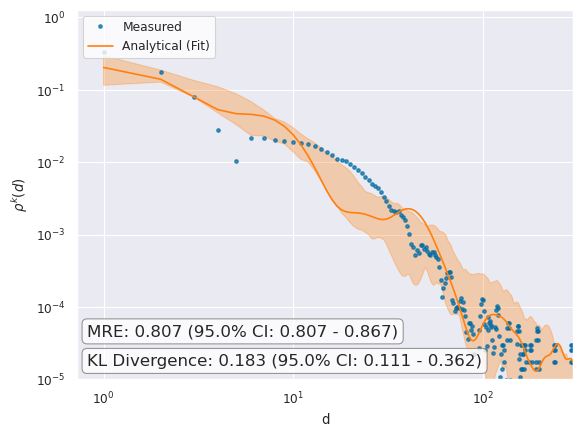

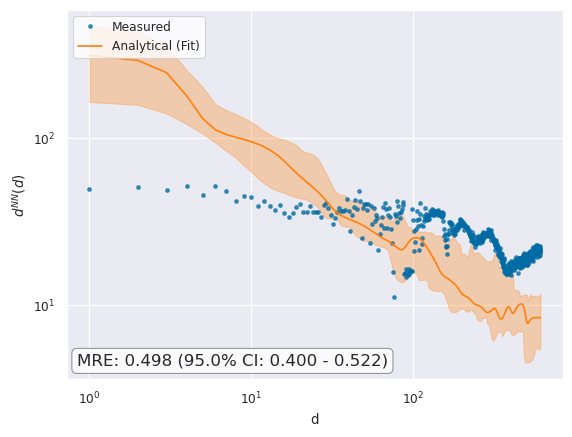

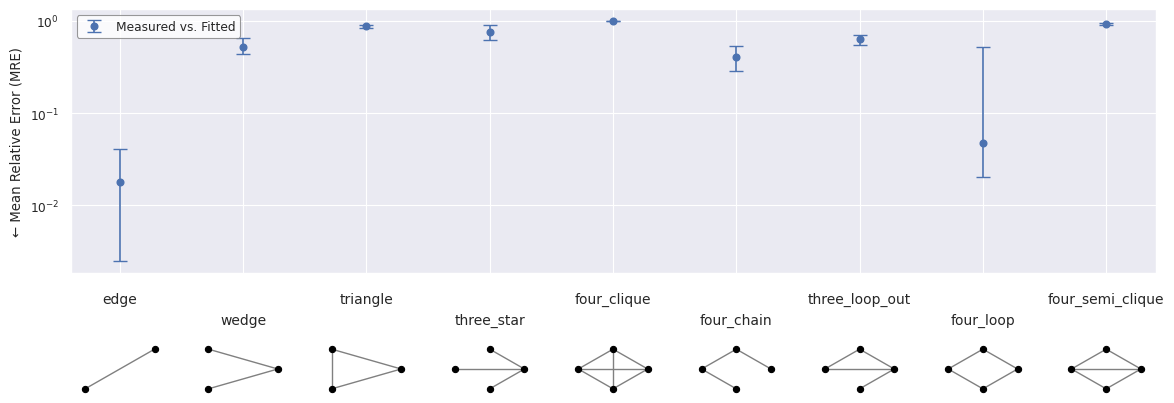

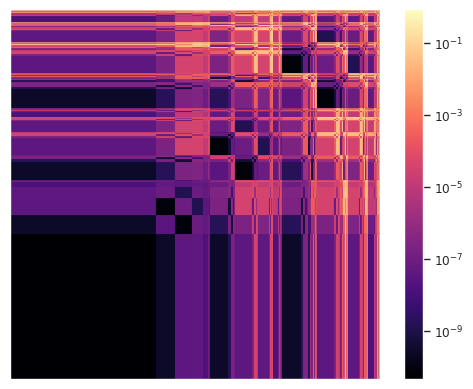

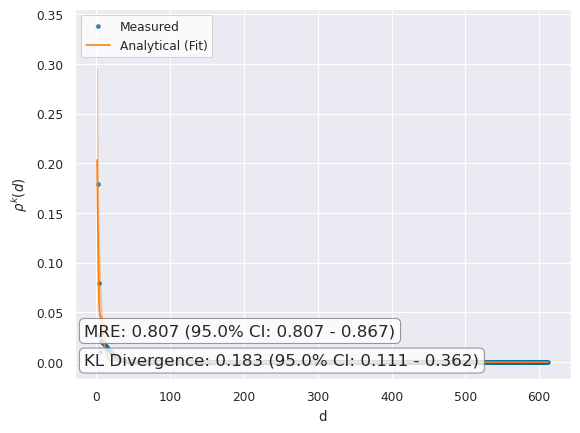

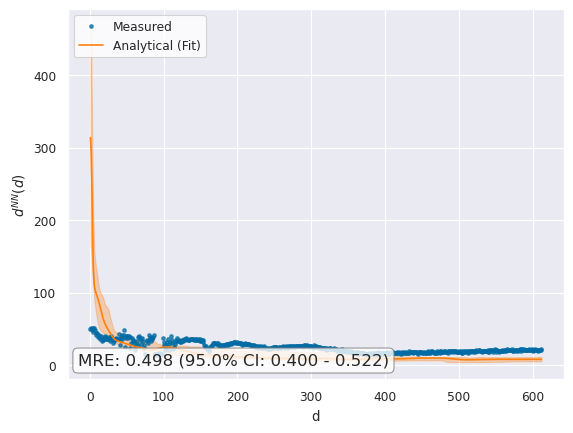

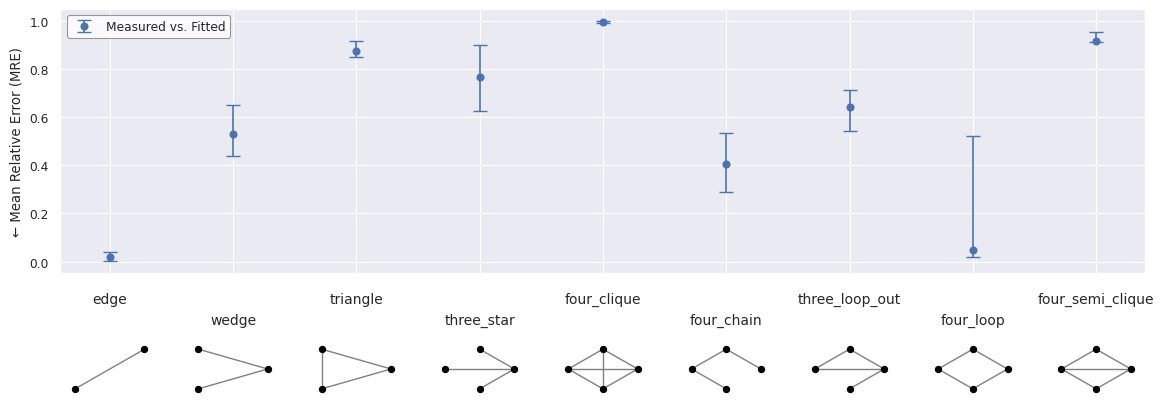

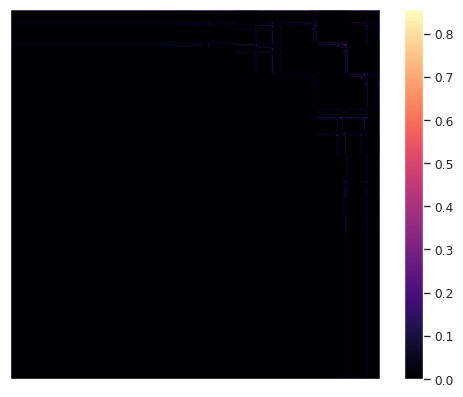

In [117]:
mfnf_no_fit.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    xlim = (0,300),
    ylim = (1e-5,0),
    filename = "figures/dblp_cite_7616_nodes_log_plot.pdf"
)

mfnf_no_fit.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/dblp_cite_7616_nodes_plot.pdf"
)

In [116]:
mfnf_no_fit.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 30041,
  'expected_count': 29505,
  'MRE': 0.017842282214307115,
  'expected_count_ci_low': 28803.0,
  'expected_count_ci_high': 30124.4,
  'MRE_ci_low': 0.0024903705671403906,
  'MRE_ci_high': 0.041210345860657104},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 1072145,
  'expected_count': 2273083,
  'MRE': 0.5283300257843643,
  'expected_count_ci_low': 1912041.8,
  'expected_count_ci_high': 3069851.0,
  'MRE_ci_low': 0.4392663514538651,
  'MRE_ci_high': 0.6507501504144664},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 24851,
  'expected_count': 3142,
  'MRE': 0.8735664560782262,
  'expected_count_ci_low': 2119.0,
  'expected_count_ci_high': 3754.0499999999984,
  'MRE_ci_low': 0.8489376685042855,
  'MRE_ci_high': 0.9147318015371615},
 {'name': 'three_star',
 